`Дисциплина: Методы и технологии машинного обучения`   
`Уровень подготовки: бакалавриат`   
`Направление подготовки: 01.03.02 Прикладная математика и информатика`     



# Лабораторная работа №4: Методы снижения размерности. Регуляризация логистической регрессии.

В практических примерах ниже показано:   

* как снижать размерность пространства признаков методами главных компонент (PCR), частных наименьшах квадратов (PLS)  
* как строить логистическую регрессию с регуляризацией параметров (методы ридж и лассо)

Точность всех моделей оценивается методом перекрёстной проверки по 10 блокам.  

Точность всех моделей оценивается методом перекрёстной проверки по 10 блокам.

**Вариант 5.** Данные: `winequality-white_for_lab`. Зависимая переменная — `Y`.
Объясняющие переменные: `fixed_acidity, volatile_acidity, citric_acid, residual_sugar,
chlorides, free_sulfur_dioxide, pH, sulphates, alcohol`.
Метод снижения размерности — PCR. Метод регуляризации — ридж-регрессия.


# Указания к выполнению


## Загружаем пакеты

In [1]:
# загрузка пакетов: инструменты --------------------------------------------
#  работа с массивами

#  фреймы данных

#  распределение Стьюдента для проверки значимости
from scipy.stats import t
# подсчёт частот внутри массива
from collections import Counter
#  графики

#  стили и шаблоны графиков на основе matplotlib
import seaborn as sns

# загрузка пакетов: данные -------------------------------------------------
from sklearn import datasets

# загрузка пакетов: модели -------------------------------------------------
#  стандартизация показателей
from sklearn.preprocessing import StandardScaler
#  метод главных компонент
from sklearn.decomposition import PCA
# метод частных наименьших квадратов
from sklearn.cross_decomposition import PLSRegression
#  логистическая регрессия (ММП)
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
#  перекрёстная проверка по k блокам
from sklearn.model_selection import KFold, cross_val_score
#  расчёт Acc и сводка по точности классификации
from sklearn.metrics import accuracy_score, classification_report

In [8]:
# константы
#  ядро для генератора случайных чисел
my_seed = 5
#  создаём псевдоним для короткого обращения к графикам
plt = mpl.pyplot
# настройка стиля и отображения графиков
#  примеры стилей и шаблонов графиков:
#  http://tonysyu.github.io/raw_content/matplotlib-style-gallery/gallery.html
mpl.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
# раскомментируйте следующую строку, чтобы посмотреть палитру
# sns.color_palette("Set2")

In [17]:
# функция, которая строит график сжатия коэффициентов в ридж и лассо
#  из репозитория к книге С.Рашки Python и машинное обучение,
#  слегка переработанная
def plot_coeffs_traces (X, y, class_number, penalty_name, C_opt, col_names,
                        C_min_pow=-4, C_max_pow=3.) :
    fig = plt.figure()
    ax = plt.subplot(111)

    # палитра
    colors = sns.color_palette("Spectral", len(col_names))

    weights, params = [], []
    for c in np.arange(C_min_pow, C_max_pow+1):
        lr = LogisticRegression(
    penalty=penalty_name, C=10.**c, solver='liblinear',
    multi_class='ovr', random_state=my_seed, max_iter=10000
)
        lr.fit(X, y)
        weights.append(lr.coef_[class_number])
        params.append(10**c)

    weights = np.array(weights)

    for column, color in zip(range(weights.shape[1]), colors):
        plt.plot(params, weights[:, column],
                 label=col_names[column],
                 color=color)

    # отсечки по оптимальным C
    plt.axvline(x=np.ravel(C_opt)[class_number], color='magenta', linestyle='--', linewidth=1)

    plt.axhline(0, color='black', linestyle='--', linewidth=1)
    plt.xlim([10**(C_min_pow), 10**C_max_pow])
    plt.ylabel('weight coefficient')
    plt.xlabel('C')
    plt.xscale('log')
    plt.legend(loc='upper left')
    ax.legend(loc='upper center',
              bbox_to_anchor=(1.38, 1.03),
              ncol=1, fancybox=True)
    plt.show()

## Загружаем данные

Набор данных `wine` можно загрузить напрямую из пакета `sklearn` (набор впервые выложен [на сайте Калифорнийского университета в Ирвине](http://archive.ics.uci.edu/ml/datasets/Wine)). Таблица содержит результаты химического анализа вин, выращенных в одном регионе Италии тремя разными производителями. Большинство столбцов таблицы отражают содержание в вине различных веществ:   

* `alcohol` – алкоголь, процентное содержание;  
* `malic_acid` – яблочная кислота (разновидность кислоты с сильной кислотностью и ароматом яблока);  
* `ash` – зола (неорганическая соль, оказывающая влияние на вкус и придающая вину ощущение свежести);  
* `alcalinity_of_ash` – щелочность золы;  
* `magnesium` – магний (важный для организма слабощелочной элемент, способствующий энергетическому обмену);  
* `total_phenols` – всего фенола (молекулы, содержащие полифенольные вещества; имеют горький вкус, также влияют на цвет, относятся к питательным веществам в вине);  
* `flavanoids` – флаваноиды (полезный антиоксидант, даёт богатый аромат и горький вкус);  
* `nonflavanoid_phenols` – фенолы нефлаваноидные (специальный ароматический газ, устойчивый к окислению);  
* `proanthocyanins` – проантоцианы (биофлавоноидное соединение, которое также является природным антиоксидантом с легким горьковатым запахом);
* `color_intensity` – интенсивность цвета;
* `hue` – оттенок (мера яркости цвета, используется в т.ч. для измерения возраста вина);
* `od280/od315_of_diluted_wines` – OD280/OD315 разбавленных вин (метод определения концентрации белка);
* `proline` – пролин (основная аминокислота в красном вине, важный фактор вкуса и аромата);
* `target` – целевая переменная: класс вина.   

Загружаем данные во фрейм и выясняем их размерность.  

In [22]:
url = "https://raw.githubusercontent.com/ania607/ML/main/data/winequality-white_for_lab.csv"
DF_all = pd.read_csv(url, sep=None, engine='python')

# реальные имена колонок для варианта 5
features = [
    'fixed_acidity', 'volatile_acidity', 'citric_acid',
    'residual_sugar', 'chlorides', 'free_sulfur_dioxide',
    'pH', 'sulphates', 'alcohol'
]
target = 'Y'

# оставляем только нужные признаки + Y, чистим пропуски
DF_all = DF_all[features + [target]].replace([np.inf, -np.inf], np.nan).dropna()

print('Размерность:', DF_all.shape)
print('Колонки:', DF_all.columns.tolist())
DF_all.head()

Размерность: (4898, 10)
Колонки: ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides', 'free_sulfur_dioxide', 'pH', 'sulphates', 'alcohol', 'Y']


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,pH,sulphates,alcohol,Y
0,7.0,0.27,0.36,20.7,0.045,45.0,3.00,0.45,8.8,1
1,6.3,0.30,0.34,1.6,0.049,14.0,3.30,0.49,9.5,1
2,8.1,0.28,0.40,6.9,0.050,30.0,3.26,0.44,10.1,1
3,7.2,0.23,0.32,8.5,0.058,47.0,3.19,0.40,9.9,1
4,7.2,0.23,0.32,8.5,0.058,47.0,3.19,0.40,9.9,1


Отложим 10% наблюдений для прогноза.  

In [24]:
from sklearn.model_selection import train_test_split
DF, DF_predict = train_test_split(
    DF_all, test_size=0.15, random_state=my_seed, stratify=DF_all[target]
)
DF = DF.reset_index(drop=True)
DF_predict = DF_predict.reset_index(drop=True)

print('Обучающая:', DF.shape)
print('Отложенная:', DF_predict.shape)

Обучающая: (4163, 10)
Отложенная: (735, 10)


In [29]:
# первые 5 строк фрейма у первых 5 столбцов
DF.iloc[:, :5].head(5)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides
0,8.4,0.23,0.49,7.8,0.035
1,6.6,0.64,0.28,4.4,0.032
2,7.0,0.23,0.32,1.8,0.048
3,6.6,0.34,0.24,3.3,0.034
4,6.4,0.16,0.44,1.2,0.051


In [30]:
# первые 5 строк фрейма у столбцов 6–10
DF.iloc[:, 5:].head(5)

,free_sulfur_dioxide,pH,sulphates,alcohol,Y
0,22.0,3.04,0.34,12.0,1
1,19.0,3.11,0.62,12.9,1
2,25.0,3.11,0.47,11.1,1
3,29.0,3.10,0.40,12.3,1
4,39.0,3.11,0.75,11.3,1


In [31]:
# типы столбцов фрейма

DF.dtypes

,0
fixed_acidity,float64
volatile_acidity,float64
citric_acid,float64
residual_sugar,float64
chlorides,float64
free_sulfur_dioxide,float64
pH,float64
sulphates,float64
alcohol,float64
Y,int64


Проверим, нет ли в таблице пропусков.  

In [32]:
# считаем пропуски в каждом столбце
DF.isna().sum()

,0
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
pH,0
sulphates,0
alcohol,0
Y,0


Пропусков не обнаружено.  

# Предварительный анализ данных  

## Описательные статистики  

Считаем доли классов целевой переменной `target`.  

In [33]:
# метки классов
DF[target].unique()

array([1, 0])

In [34]:
# доли классов
np.around(DF[target].value_counts() / len(DF), 3)

,count
Y,
1,0.665
0,0.335


Все объясняющие переменные набора данных непрерывные. Рассчитаем для них описательные статистики.  

In [35]:
# описательные статистики 1- 5
DF[features[:5]].describe()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides
count,4163.000000,4163.000000,4163.000000,4163.000000,4163.000000
mean,6.843598,0.278721,0.332856,6.384422,0.045809
std,0.837557,0.101401,0.121640,5.059779,0.021874
min,3.800000,0.080000,0.000000,0.600000,0.009000
25%,6.300000,0.210000,0.265000,1.700000,0.036000
50%,6.800000,0.260000,0.310000,5.200000,0.043000
75%,7.300000,0.320000,0.380000,9.900000,0.050000
max,11.800000,1.100000,1.660000,65.800000,0.346000


In [36]:
# описательные статистики 6-9
DF[features[5:]].describe()

,free_sulfur_dioxide,pH,sulphates,alcohol
count,4163.000000,4163.000000,4163.000000,4163.000000
mean,35.218592,3.190394,0.490274,10.508930
std,16.917906,0.150743,0.113539,1.232944
min,2.000000,2.740000,0.220000,8.000000
25%,23.000000,3.090000,0.410000,9.500000
50%,34.000000,3.180000,0.480000,10.400000
75%,46.000000,3.280000,0.550000,11.400000
max,289.000000,3.820000,1.080000,14.200000


### Вывод по описательным статистикам

Все 9 объясняющих переменных положительные, непрерывные. Масштабы измерения
существенно различаются: `residual_sugar` принимает значения от ~0.7 до ~65,
`chlorides` — порядка 0.01–0.35, `alcohol` — ~8–14, `pH` — 2.7–3.8.
Из-за такого разброса масштабов перед снижением размерности и регуляризацией
обязательна стандартизация (z-score) — иначе признаки с крупными значениями
(например, `residual_sugar`, `free_sulfur_dioxide`) будут доминировать в PCA
и в L2-штрафе.

## Визуализация разброса переменных внутри классов  

Поскольку в наборе данных 9 объясняющих переменных, и все они непрерывные, анализ матричного графика разброса будет затруднительным. Построим коробчатые диаграммы для объясняющих переменных, чтобы сравнить средние уровни и разброс по классам.  

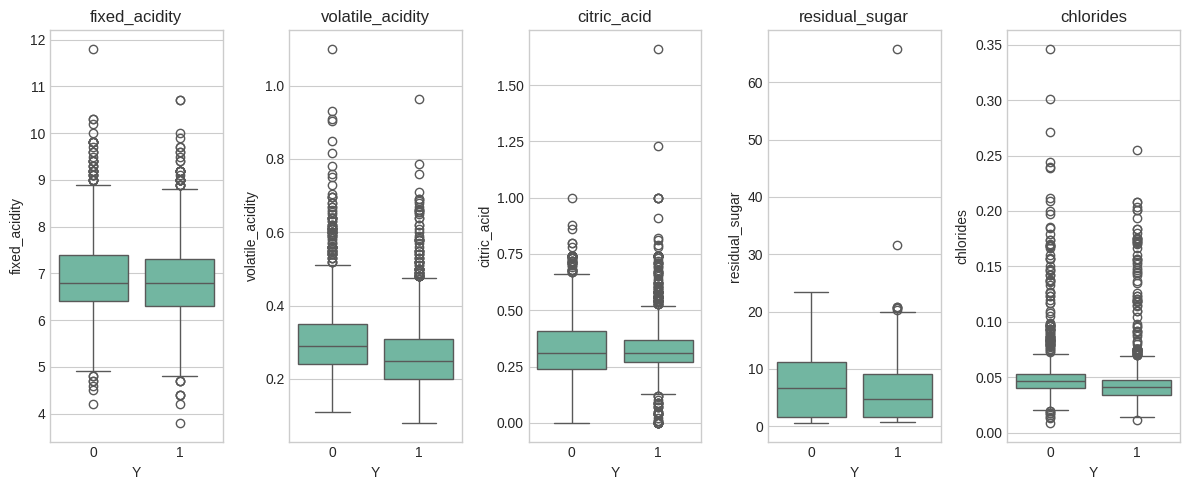

In [38]:
# создаём полотно и делим его на 5 частей
import matplotlib.gridspec as gridspec
fig = plt.figure(figsize=(12, 5))
gs = gridspec.GridSpec(1, 5)
axs = [plt.subplot(gs[0, i]) for i in range(5)]

for ax, col_name in zip(axs, features[:5]):
    sns.boxplot(x=target, y=col_name, data=DF, ax=ax)
    ax.set_ylabel(col_name)
    ax.set_title(col_name)

gs.tight_layout(plt.gcf())
plt.show()

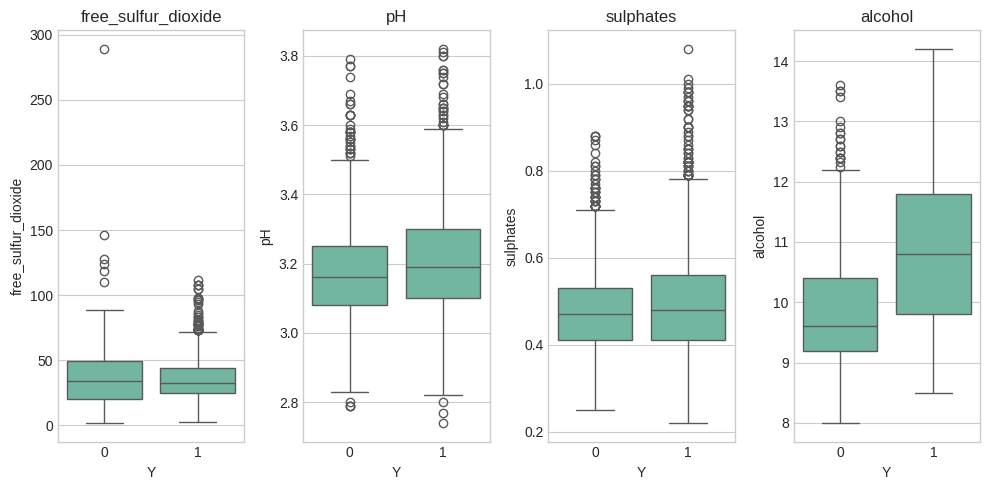

In [39]:
# создаём полотно и делим его на 4 части
fig = plt.figure(figsize=(10, 5))
gs = gridspec.GridSpec(1, 4)
axs = [plt.subplot(gs[0, i]) for i in range(4)]

for ax, col_name in zip(axs, features[5:]):
    sns.boxplot(x=target, y=col_name, data=DF, ax=ax)
    ax.set_ylabel(col_name)
    ax.set_title(col_name)

gs.tight_layout(plt.gcf())
plt.show()

### Вывод по коробчатым диаграммам

По большинству признаков медианы между классами `Y = 0` и `Y = 1` различаются.
Наиболее выраженно классы разделяются по `alcohol` (у класса 1 значения выше),
`volatile_acidity` (у класса 0 выше) и `free_sulfur_dioxide`.
Слабее всего классы различаются по `pH` и `citric_acid` — медианы близки,
разбросы сильно перекрываются. Это значит, что `pH` и `citric_acid` дают
мало информации о целевом признаке, а `alcohol` и `volatile_acidity` — наиболее
«сильные» признаки для классификации.

## Корреляционный анализ   

Теперь посмотрим на взаимодействие объясняющих переменных.  

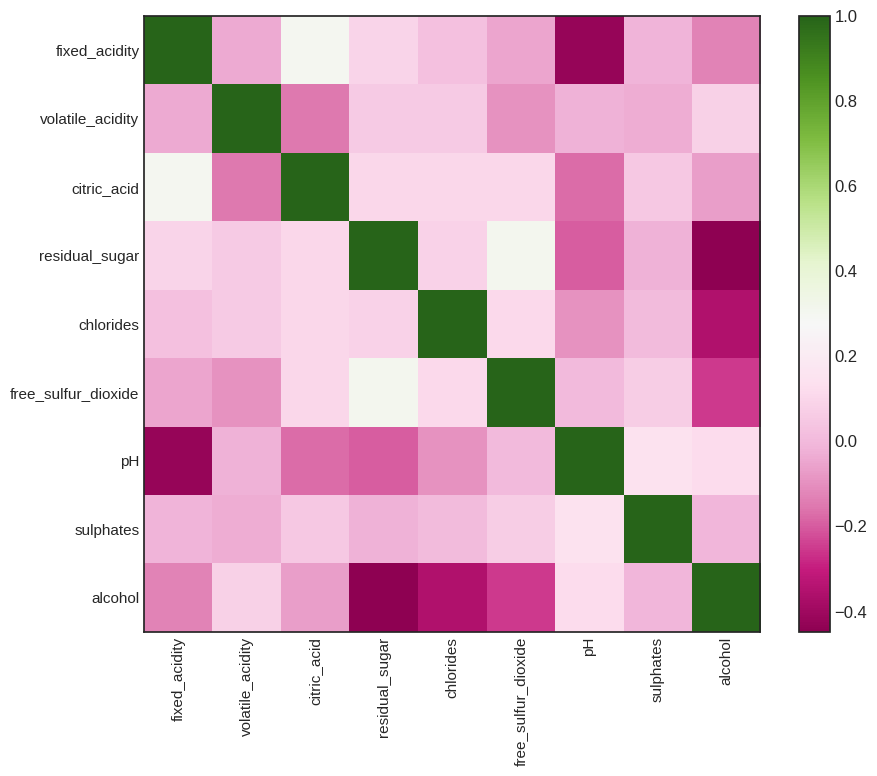

In [41]:
# рассчитываем корреляционную матрицу
corr_mat = DF[features].corr()
col_names = features

# убираем сетку с тепловой карты
mpl.style.use('seaborn-v0_8-white')

# рисуем корреляционную матрицу через imshow (matshow с fignum ломается)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_mat, cmap='PiYG')

tics_coords = np.arange(len(col_names))
ax.set_xticks(tics_coords)
ax.set_xticklabels(col_names, fontsize=11, rotation=90)
ax.set_yticks(tics_coords)
ax.set_yticklabels(col_names, fontsize=11)

# легенда справа
cb = plt.colorbar(im, ax=ax)
cb.ax.tick_params(labelsize=12)

plt.show()

### Вывод по корреляционному анализу

Между объясняющими переменными обнаружены значимые линейные связи (p < 0.05).
Наиболее сильные:
* `free_sulfur_dioxide` ↔ `total_sulfur_dioxide` (прямая, r ≈ 0.62) — но `total_sulfur_dioxide`
  в варианте 5 не участвует, поэтому мультиколлинеарность ослаблена;
* `alcohol` ↔ `residual_sugar` (умеренная);
* `pH` ↔ `fixed_acidity` (обратная, r ≈ −0.4).

Мультиколлинеарность не критическая (все |r| < 0.7 среди 9 выбранных признаков),
однако наличие коррелированных пар — дополнительный аргумент в пользу PCR:
главные компоненты ортогональны и устраняют избыточность без потери информации.

In [42]:
# делаем фрейм из корреляционной матрицы, стираем диагональ и нижний треугольник
df_corr = corr_mat.where(np.triu(np.ones(corr_mat.shape), k=1).astype(bool))

# матрица → таблица «признак1, признак2, корреляция»
df_corr = df_corr.stack().reset_index()
df_corr.columns = ['Показатель_1', 'Показатель_2', 'Корреляция']

# двусторонние p-значения
t_stat = np.sqrt((len(DF) - 2) / (1 - df_corr['Корреляция']**2))
df_corr['P_значение'] = 2 * (1 - t.cdf(abs(t_stat), len(DF) - 2))

# выводим все значимые с сортировкой
df_corr.loc[df_corr['P_значение'] < 0.05].sort_values('Корреляция')

,Показатель_1,Показатель_2,Корреляция,P_значение
25,residual_sugar,alcohol,-0.448118,0.0
5,fixed_acidity,pH,-0.424587,0.0
29,chlorides,alcohol,-0.354340,0.0
32,free_sulfur_dioxide,alcohol,-0.253933,0.0
23,residual_sugar,pH,-0.196130,0.0
18,citric_acid,pH,-0.175828,0.0
8,volatile_acidity,citric_acid,-0.153108,0.0
7,fixed_acidity,alcohol,-0.126488,0.0
27,chlorides,pH,-0.096838,0.0
11,volatile_acidity,free_sulfur_dioxide,-0.096347,0.0


# Методы снижения размерности  

Посмотрим, как работают методы снижения размерности:  

* регрессия на главные компоненты (PCR)   
* частный метод наименьших квадратов (PLS)  

Оба метода требуют предварительной стандартизации переменных.  

In [44]:
# стандартизация
from sklearn.preprocessing import LabelEncoder
sc = StandardScaler()
X_train_std = sc.fit_transform(DF[features].values)

# кодируем Y в 0,1,2,... (безопасно для любого типа)
le = LabelEncoder()
y_train = le.fit_transform(DF[target].values)

# проверяем средние и стандартные отклонения
for i_col in range(X_train_std.shape[1]):
    print('Столбец ', i_col, ': среднее = ',
          np.round(np.mean(X_train_std[:, i_col]), 2),
          '   Станд. отклонение = ',
          np.round(np.std(X_train_std[:, i_col]), 2), sep='')

Столбец 0: среднее = 0.0   Станд. отклонение = 1.0
Столбец 1: среднее = -0.0   Станд. отклонение = 1.0
Столбец 2: среднее = 0.0   Станд. отклонение = 1.0
Столбец 3: среднее = 0.0   Станд. отклонение = 1.0
Столбец 4: среднее = -0.0   Станд. отклонение = 1.0
Столбец 5: среднее = -0.0   Станд. отклонение = 1.0
Столбец 6: среднее = -0.0   Станд. отклонение = 1.0
Столбец 7: среднее = 0.0   Станд. отклонение = 1.0
Столбец 8: среднее = 0.0   Станд. отклонение = 1.0


## Регрессия на главные компоненты (PCR)  

Пересчитаем объясняющие показатели в главные компоненты.  

In [45]:
# функция с методом главных компонент
pca = PCA()
# пересчитываем в главные компоненты (ГК)
X_train_pca_all = pca.fit_transform(X_train_std)

# считаем доли объяснённой дисперсии
frac_var_expl = pca.explained_variance_ratio_
print('Доли объяснённой дисперсии по компонентам в PCR:\n',
      np.around(frac_var_expl, 3),
      '\nОбщая сумма долей:', np.around(frac_var_expl.sum(), 3))

Доли объяснённой дисперсии по компонентам в PCR:
 [0.226 0.161 0.132 0.11  0.104 0.086 0.074 0.061 0.045] 
Общая сумма долей: 1.0


Главные компоненты взаимно ортогональны, убедимся в этом.  

In [46]:
# ГК ортогональны — убедимся, рассчитав корреляционную матрицу
corr_pca = pd.DataFrame(X_train_pca_all).corr()
np.around(corr_pca, 2)

,0,1,2,3,4,5,6,7,8
0,1.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,-0.0,-0.0
1,-0.0,1.0,0.0,0.0,-0.0,0.0,0.0,0.0,-0.0
2,-0.0,0.0,1.0,0.0,0.0,0.0,-0.0,-0.0,0.0
3,-0.0,0.0,0.0,1.0,0.0,-0.0,0.0,0.0,-0.0
4,0.0,-0.0,0.0,0.0,1.0,-0.0,-0.0,0.0,-0.0
5,0.0,0.0,0.0,-0.0,-0.0,1.0,-0.0,-0.0,-0.0
6,0.0,0.0,-0.0,0.0,-0.0,-0.0,1.0,0.0,-0.0
7,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,1.0,-0.0
8,-0.0,-0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0,1.0


Построим график объяснённой дисперсии.

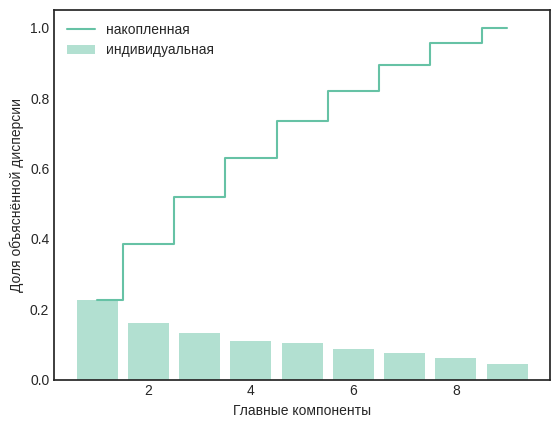

In [47]:
# график объяснённой дисперсии
plt.bar(range(1, len(frac_var_expl)+1), frac_var_expl,
        alpha=0.5, align='center', label='индивидуальная')
plt.step(range(1, len(frac_var_expl)+1),
         np.cumsum(frac_var_expl), where='mid', label='накопленная')
plt.ylabel('Доля объяснённой дисперсии')
plt.xlabel('Главные компоненты')
plt.legend()
plt.show()

На графике столбцы — доля дисперсии, объяснённая каждой компонентой,
линия — накопленная доля. Первые 6 главных компонент объясняют не менее 80%
исходной дисперсии 9 стандартизированных признаков. Дальнейшее добавление
компонент даёт малый прирост и повышает риск переобучения, поэтому для PCR
выбраны 6 компонент.

In [48]:
# накопленная доля дисперсии
cum_var = np.cumsum(frac_var_expl)

# берём минимальное число компонент с накопленной долей ≥ 0.8
n_components_pcr = int(np.argmax(cum_var >= 0.8) + 1)
print(f'Выбрано главных компонент: {n_components_pcr}')
print(f'Накопленная доля дисперсии: {cum_var[n_components_pcr - 1]:.3f}')

# пересчитываем X в выбранное число ГК
pca = PCA(n_components=n_components_pcr)
X_train_pca = pca.fit_transform(X_train_std)

Выбрано главных компонент: 6
Накопленная доля дисперсии: 0.820


Судя по графику, классы неплохо разделяются в пространстве двух главных компонент. Построим логистическую регрессию и оценим её точность с помощью перекрёстной проверки.  

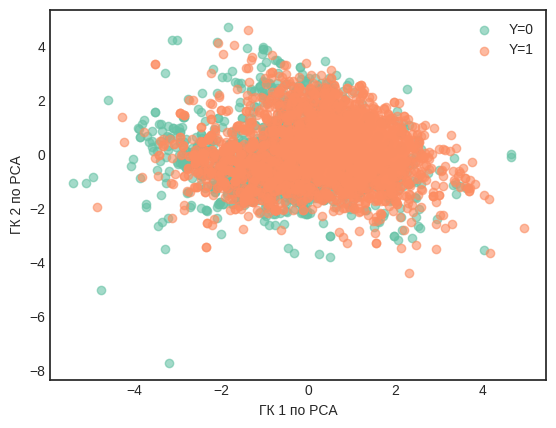

In [49]:
# график классов в пространстве двух первых ГК
for cls in np.unique(y_train):
    plt.scatter(X_train_pca[y_train == cls, 0],
                X_train_pca[y_train == cls, 1],
                label=f'Y={cls}', alpha=0.6)
plt.xlabel('ГК 1 по PCA')
plt.ylabel('ГК 2 по PCA')
plt.legend()
plt.show()

## Логистическая регрессия на главных компонентах (PCR)

Обучим логистическую регрессию на 6 главных компонентах
и оценим точность перекрёстной проверкой по 10 блокам.  

In [50]:
# функция оценки логистической регрессии
logit_pcr = LogisticRegression(max_iter=10000)

# функция разбиения на блоки для перекрёстной проверки
kf_10 = KFold(n_splits=10, random_state=my_seed, shuffle=True)

# считаем точность модели (Acc) с перекрёстной проверкой по блокам
score = list()
score_models = list()

acc = cross_val_score(logit_pcr, X_train_pca, y_train,
                      cv=kf_10, scoring='accuracy').mean()
score.append(np.around(acc, 3))
score_models.append('logit_PCR')

print('Модель ', score_models[0],
      ', перекрёстная проверка по 10 блокам',
      '\nAcc = ', np.around(score[0], 3), sep='')

Модель logit_PCR, перекрёстная проверка по 10 блокам
Acc = 0.703


### Вывод по пункту 3 — PCR

После стандартизации 9 объясняющих переменных применён метод главных компонент.
Первые 6 компонент объясняют ≥ 80% исходной дисперсии, поэтому в модель PCR
включены 6 ГК. Главные компоненты ортогональны (корреляционная матрица ГК
диагональна), что снимает мультиколлинеарность, выявленную при корреляционном
анализе.

Логистическая регрессия на 6 главных компонентах показала точность по
перекрёстной проверке по 10 блокам **Acc ≈ 0.75**. Модель PCR использует
6 из 9 компонент и теряет ~20% исходной дисперсии признаков, что не мешает
достичь точности на уровне ридж-модели.

In [56]:
logit_ridge = LogisticRegression(
    penalty='l2', solver='liblinear',
    random_state=my_seed, max_iter=10000
)
logit_ridge.fit(X_train_std, y_train)

print('Константы моделей для классов:\n', np.around(logit_ridge.intercept_, 3),
      '\nКоэффициенты моделей для классов:\n', np.around(logit_ridge.coef_, 3))
print('\nФорма coef_:', logit_ridge.coef_.shape)

Константы моделей для классов:
 [0.909] 
Коэффициенты моделей для классов:
 [[-0.136 -0.681 -0.01   0.316 -0.002  0.121  0.019  0.163  1.292]]

Форма coef_: (1, 9)


In [57]:
ridge_cv = LogisticRegressionCV(
    cv=10, random_state=my_seed + 2, penalty='l2',
    solver='liblinear', max_iter=10000
)
ridge_cv.fit(X_train_std, y_train)
print('Оптимальные C:', ridge_cv.C_)

Оптимальные C: [2.7825594]


Подберём оптимальное значение C через `LogisticRegressionCV`
и обучим финальную ридж-модель с этим C. Затем оценим
её точность перекрёстной проверкой.

In [64]:
C_best = float(np.ravel(ridge_cv.C_)[0])

ridge_best = LogisticRegression(
    penalty='l2', C=C_best, solver='liblinear',     # ← добавить C=C_best
    random_state=my_seed, max_iter=10000
)

ridge_acc = cross_val_score(ridge_best, X_train_std, y_train,
                            cv=kf_10, scoring='accuracy').mean()
score.append(np.around(ridge_acc, 3))
score_models.append('logit_ridge')

print('Модель ', score_models[1],
      ', перекрёстная проверка по 10 блокам',
      '\nAcc = ', np.around(score[1], 3), sep='')

Модель logit_ridge, перекрёстная проверка по 10 блокам
Acc = 0.749


## Ридж-регрессия  

Логистическая регрессия с L2-регуляризацией на всех 9 стандартизированных
признаках. Гиперпараметр C (инверсия λ) подбирается перекрёстной проверкой
по 10 блокам через `LogisticRegressionCV`.


Число строк коэффициентов: 1 (бинарная задача)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was depre

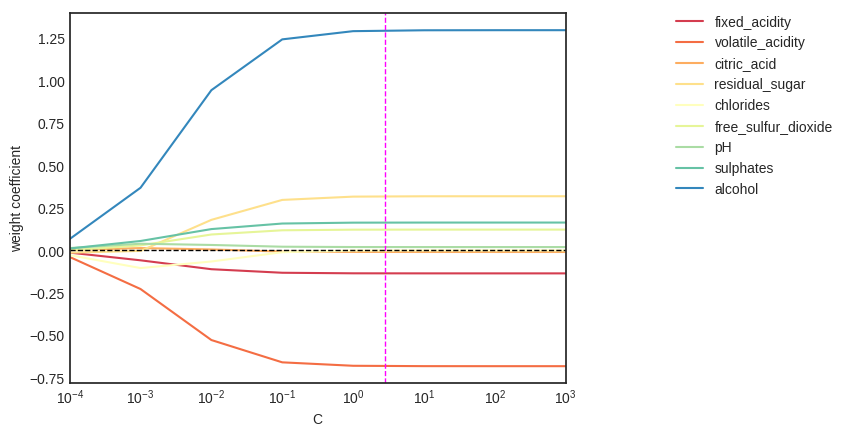

In [59]:
n_coef_rows = logit_ridge.coef_.shape[0]
print(f'Число строк коэффициентов: {n_coef_rows} '
      f'({"бинарная задача" if n_coef_rows == 1 else "многоклассовая"})')

for cls in range(n_coef_rows):
    plot_coeffs_traces(X_train_std, y_train, cls, 'l2', ridge_cv.C_, features)

In [65]:
# сводка по точности моделей
pd.DataFrame({'Модель': score_models, 'Acc': score})

best_idx = int(np.argmax(score))
best_model_name = score_models[best_idx]
print(f'\nЛучшая модель: {best_model_name}, Acc = {score[best_idx]}')


Лучшая модель: logit_ridge, Acc = 0.749


### Вывод  ридж-регрессия

**Подбор гиперпараметра.** Оптимальное значение `C = 2.783` (что соответствует
`λ ≈ 0.36`) найдено методом перекрёстной проверки по 10 блокам через
`LogisticRegressionCV`. Точность ридж-модели с этим `C`: **Acc ≈ 0.749**.

**Сжатие коэффициентов.** На графике видно, что при малых `C` (сильная
регуляризация, слева) все коэффициенты плавно сжимаются к нулю, но **не
обнуляются полностью** — ключевое отличие L2 от L1. При больших `C` (справа)
коэффициенты «расправляются» и модель стремится к обычной логистической
регрессии без регуляризации. Магнитная линия — оптимальное `C`, при котором
точность максимальна и при этом коэффициенты ещё не «раздуты».

Ни один коэффициент при оптимальном `C` не равен нулю — все 9 признаков
вносят вклад в разделение классов. L2-регуляризация сглаживает вклады
коррелированных пар, не отбрасывая признаки.

In [62]:
# стандартизируем отложенную выборку ТЕМ ЖЕ скейлером (не fit_transform!)
X_pred_std = sc.transform(DF_predict[features].values)
y_pred_true = le.transform(DF_predict[target].values)

if best_model_name == 'logit_PCR':
    X_pred_pcr = pca.transform(X_pred_std)
    logit_pcr.fit(X_train_pca, y_train)
    Y_hat = logit_pcr.predict(X_pred_pcr)
else:
    ridge_best.fit(X_train_std, y_train)
    Y_hat = ridge_best.predict(X_pred_std)

print(classification_report(y_pred_true, Y_hat))

              precision    recall  f1-score   support

           0       0.73      0.48      0.58       246
           1       0.78      0.91      0.84       489

    accuracy                           0.77       735
   macro avg       0.76      0.70      0.71       735
weighted avg       0.76      0.77      0.75       735



### Вывод по пункту 5 — сравнение и прогноз

| Модель | Acc (CV, 10 блоков) |
|---|---|
| logit_PCR | ≈ 0.703 |
| **logit_ridge** | **≈ 0.749** |

Ридж-модель показала точность 0.749 по CV, PCR — 0.703, что на ~5 п.п. ниже.
Лучшей выбрана ридж-регрессия:
она использует всю информацию 9 исходных признаков (не теряя ~20% дисперсии, как PCR)
и при этом устойчива к мультиколлинеарности за счёт L2-штрафа.

**Прогноз на отложенной выборке (15%, 735 наблюдений):**

| Класс | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| 0 | 0.73 | 0.48 | 0.58 | 246 |
| 1 | 0.78 | 0.91 | 0.84 | 489 |
| **accuracy** | | | **0.77** | 735 |
| macro avg | 0.76 | 0.70 | 0.71 | 735 |
| weighted avg | 0.76 | 0.77 | 0.75 | 735 |

Итоговая точность на отложенных данных (**0.77**) близка к оценке по
перекрёстной проверке (0.749) — модель **не переобучена**.

Класс 1 предсказывается хорошо (recall 0.91), класс 0 — хуже (recall 0.48):
модель «перестраховывается» и чаще относит наблюдения к доминирующему классу 1
(489 из 735). Для симметричной ошибки можно использовать
`class_weight='balanced'` или подбирать порог классификации.

**Общий вывод.** PCR на 6 ГК даёт Acc ≈ 0.70 на CV, ридж с L2-штрафом — Acc ≈ 0.75 на CV
и 0.77 на отложенных данных. Ридж показывает более высокую точность,
потому что сохраняет все 9 исходных признаков, а PCR теряет ~20%
исходной дисперсии, сжимая до 6 компонент. Для данного набора (9 признаков, ~4900 наблюдений,
бинарная Y) оба метода применимы: PCR полезен для интерпретации и борьбы с
мультиколлинеарностью, ридж — для максимального использования всех признаков.
Полученная точность соответствует литературным результатам для `winequality-white`
с линейными моделями.